In [ ]:
import re, json, os, time, zipfile, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from scipy.stats import kruskal
from IPython.display import display, Markdown

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer, normalize
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.metrics import (f1_score, accuracy_score, cohen_kappa_score, confusion_matrix,
                             normalized_mutual_info_score, adjusted_rand_score, homogeneity_score)
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from joblib import Parallel, delayed

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = Path('dataset')
ZIP_PATH = Path('dataset.zip')
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)

if not DATA_DIR.exists():
    assert ZIP_PATH.exists(), 'Put dataset.zip (or the extracted dataset/ folder) next to the notebook.'
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('.')
print('data dir:', DATA_DIR.resolve())

data dir: /content/dataset


## 0. Load and join

The dataset consists of 3 file types:
- `subforums.csv` lists all the subforums which are equivalent to topics. There are 31 topics in total. Each topic has an `id`.

- `threads_{id}.csv`: list of questions (threads) in a given topic with id = `{id}`. Contains metadata like  dates, author, replies, last replier type (consultant, user)

- `questions_{id}.csv` - a CSV containing the full question title & text for each thread in a given topic with id = `{id}`

In [ ]:
def read_subforums(path):
    rows = []
    for line in Path(path).read_text(encoding='utf-8-sig').splitlines():
        if line.strip():
            i, name = line.split(',', 1)
            rows.append((int(i), name.strip()))

    return pd.Series(dict(rows), name='subforum_name')

SUBFORUM_NAMES = read_subforums(DATA_DIR / 'subforums.csv')

# Short labels
TOPIC_SHORT_LABELS = {
    10: 'Companies', 14: 'Civil/inheritance/property', 15: 'Labour law', 17: 'IT & internet',
    18: 'Local taxes', 20: 'Family', 21: 'B2B contracts', 22: 'Criminal law',
    26: 'Administrative/authorities', 33: "Owners' associations", 38: 'Insolvency', 52: 'NGOs',
    54: 'Traffic code', 55: 'Enforcement', 63: 'IP', 70: 'Debt & banks', 71: 'Consumer',
    77: 'Pensions', 78: 'Civil servants', 79: 'Insurance', 81: 'EU funds', 85: 'Expert reports',
    88: 'PFA/II/AF', 89: 'Unemployment & social', 104: 'ID & civil status', 105: 'OSH',
    106: 'Land registry', 107: 'Civil procedure', 108: 'Criminal procedure', 111: 'Mediation',
    116: 'Education',
}
def topic_short_label(i): return f'{i} {TOPIC_SHORT_LABELS.get(i, SUBFORUM_NAMES.get(i, ""))}'

In [ ]:
questions = pd.concat([pd.read_csv(f) for f in sorted(DATA_DIR.glob('questions_*.csv'))], ignore_index=True)
threads   = pd.concat([pd.read_csv(f) for f in sorted(DATA_DIR.glob('threads_*.csv'))],   ignore_index=True)
print(f'questions: {questions.shape}, threads: {threads.shape}, subforums listed: {len(SUBFORUM_NAMES)}')

missing_q = threads[~threads.thread_id.isin(questions.thread_id)]
print(f'threads without a question text: {len(missing_q)}')
display(missing_q[['thread_id', 'subforum_id', 'title', 'creation_date', 'is_sticky']])

df = threads.merge(questions[['thread_id', 'subforum_id', 'full_title', 'full_question']],
                   on='thread_id', how='inner', suffixes=('', '_q'))
assert (df.subforum_id == df.subforum_id_q).all(), 'label mismatch between listing and question files'
df = df.drop(columns='subforum_id_q')

print('stickies dropped:', int(df.is_sticky.sum()))
df = df[df.is_sticky == 0].reset_index(drop=True)

for c in ['creation_date', 'last_reply_date']:
    df[c] = pd.to_datetime(df[c])
df['listed_at'] = pd.to_datetime(df['listed_at'], utc=True).dt.tz_localize(None)
df['text'] = df['full_question'].fillna('').str.strip()
df['label'] = df['subforum_id'].astype(int)
LABELS = sorted(df.label.unique())
K = len(LABELS)
print(f'final rows: {len(df):,}, classes: {K}')
missing_names = set(SUBFORUM_NAMES.index) - set(LABELS)
print('subforums in subforums.csv with no data:', {i: SUBFORUM_NAMES[i] for i in missing_names} or 'none')

questions: (17052, 5), threads: (17053, 23), subforums listed: 31
threads without a question text: 1


,thread_id,subforum_id,title,creation_date,is_sticky
2180,805792,106,NaN,2023-02-15T11:13,0


stickies dropped: 1
final rows: 17,051, classes: 31
subforums in subforums.csv with no data: none


### 1. Text normalisation

Every lexical feature will work on a **normalised** copy: lowercased, no diacritics, alphabetical tokens only.

#### Diacritics

Because not all posts use diacritics we should strip them.

#### Redacted text and formatting tokens

We observed the following instances but less than 0.32% questions include them at least once.

- `[email protected]`
- `**<bold text>**`
- `***` or more for redacted information

Since we are keeping only alphabetical tokens (`[a-z]+`) we're removing these instances by design.

In [ ]:
def strip_diacritics(text):
    return ''.join(c for c in unicodedata.normalize('NFKD', text) if not unicodedata.combining(c))

def normalize_text(text):
  lowercased = text.lower();

  return strip_diacritics(lowercased)

df['title_question'] = df['title'].fillna('') + '\n\n' + df['text'].fillna('')

df['text_norm'] = df['text'].map(normalize_text)
df['title_norm'] = df['title'].map(normalize_text)
df['title_question_norm'] = df['title_question'].map(normalize_text)


# Keep just alphabetical tokens
TOKEN_RE = re.compile(r'[a-z]+')
df['question_tokens'] = df['text_norm'].map(TOKEN_RE.findall)
df['title_tokens'] = df['title_norm'].map(TOKEN_RE.findall)
df['title_question_tokens'] = df['title_question_norm'].map(TOKEN_RE.findall)

### 2. Dataset descriptive analysis

#### 2.1 Size
The dataset contains `17,052` questions across `31` topics.

The entries go back as far as `2020-01-01`, each topic being capped at `~600` questions.

The 600 threshold was not reached for all topics, leaving us with the following choices:
- drop all topics < 600
- try to expand the crawl time window
- lower the threshold to include more classes

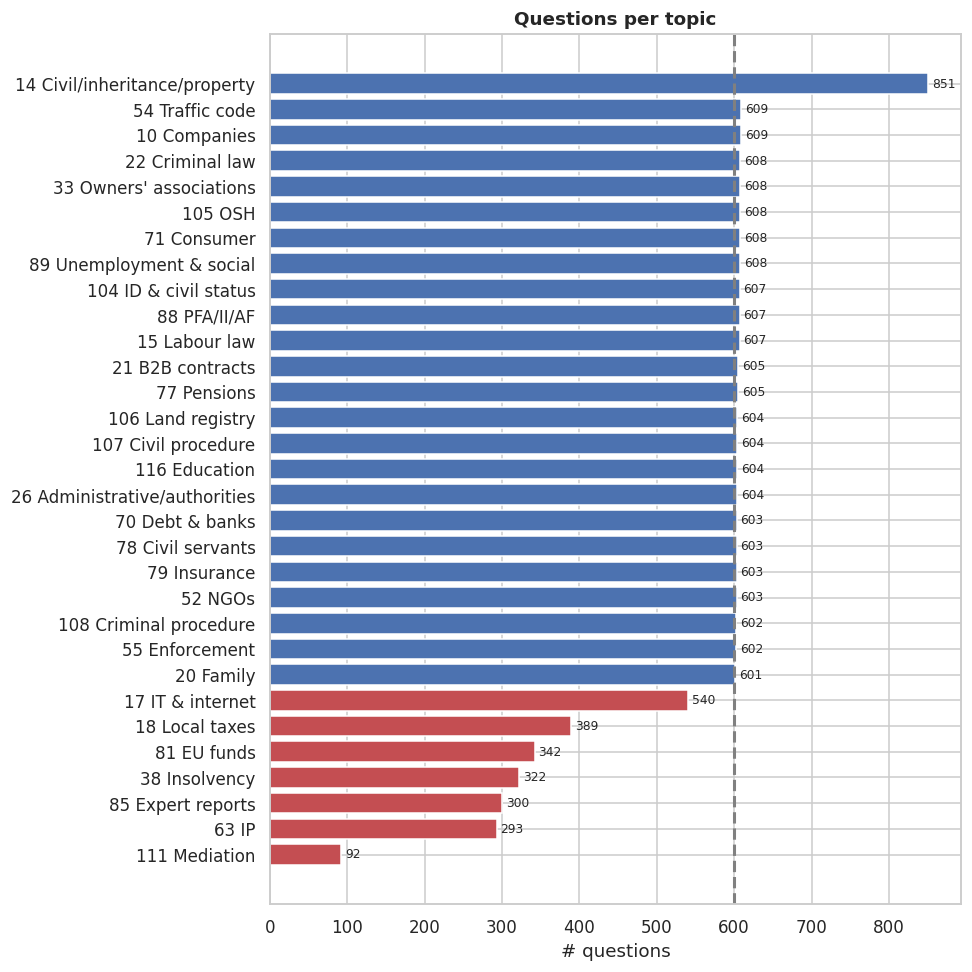

In [ ]:
cnt = df.label.value_counts().sort_values()
span = df.groupby('label').creation_date.agg(['min', 'max'])
fig, ax = plt.subplots(figsize=(9, 9))
ax.barh([topic_short_label(i) for i in cnt.index], cnt.values, color=['#c44e52' if v < 550 else '#4c72b0' for v in cnt.values])
ax.axvline(x = 600, color = 'grey', label = 'threshold', ls='--', lw=2)

for y, v in enumerate(cnt.values): ax.text(v + 5, y, str(v), va='center', fontsize=8)
ax.set_title('Questions per topic'); ax.set_xlabel('# questions'); plt.tight_layout(); plt.show()


In [ ]:
mean_questions = cnt.mean()
std_questions = cnt.std()

print(f"Mean number of questions per topic: {mean_questions:.1f}")
print(f"Standard deviation of questions per topic: {std_questions:.2f}")

Mean number of questions per topic: 550.0
Standard deviation of questions per topic: 143.84


#### 2.2 Structure
For any given `(question, topic)` pair we've captured the following information:

In [ ]:
example = df[(df["nr_messages"] > 2) & df["last_replier_label"].notna() & (df["is_sticky"] == 0)].iloc[0]

def short(v, n=80):
    s = str(v).replace("\n", " ")
    return s if len(s) <= n else s[:n] + "…"

columns_table = pd.DataFrame({
    "column": df.columns,
    "type": [str(t) + (", nullable" if df[c].isna().any() else "") for c, t in df.dtypes.items()],
    "example": [short(example[c]) for c in df.columns],
})

with pd.option_context("display.max_colwidth", None):
    display(columns_table.style.hide(axis="index").set_properties(**{"text-align": "left"}))

column,type,example
thread_id,int64,878821
first_post_id,int64,3709904
subforum_id,int64,10
title,object,SRL pentru vanzare online produse printate de noi cu imprimanta 3d
url,object,https://www.avocatnet.ro/forum/discutie_878821/SRL-pentru-vanzare-online-produse…
is_locked,int64,0
creation_date,datetime64[ns],2026-10-30 18:59:00
creation_date_raw,object,"18:59, 30 Octombrie 2026"
last_reply_date,"datetime64[ns], nullable",2026-11-01 20:11:00
last_reply_date_raw,"object, nullable","20:11, 1 Noiembrie 2026"


We will further pre-process the raw data and generate a series of features derived from the question title & content.


#### 2.3 Question Authors

Some authors are more prolific than others and contribute to a larger share of questions across the dataset.

This could potentially lead to leakage if a prolific author posts predominantly in one topic hence his writing style becoming a proxy for the question's topic.


,threads and authors
threads,17051
authors,12664


,threads per author
p50,1.000000
p75,1.000000
p90,2.000000
p95,3.000000
p99,6.000000
p99.9,19.000000
max,65.000000
authors with 1 thread,10607.000000
authors with 1 thread (%),0.837571


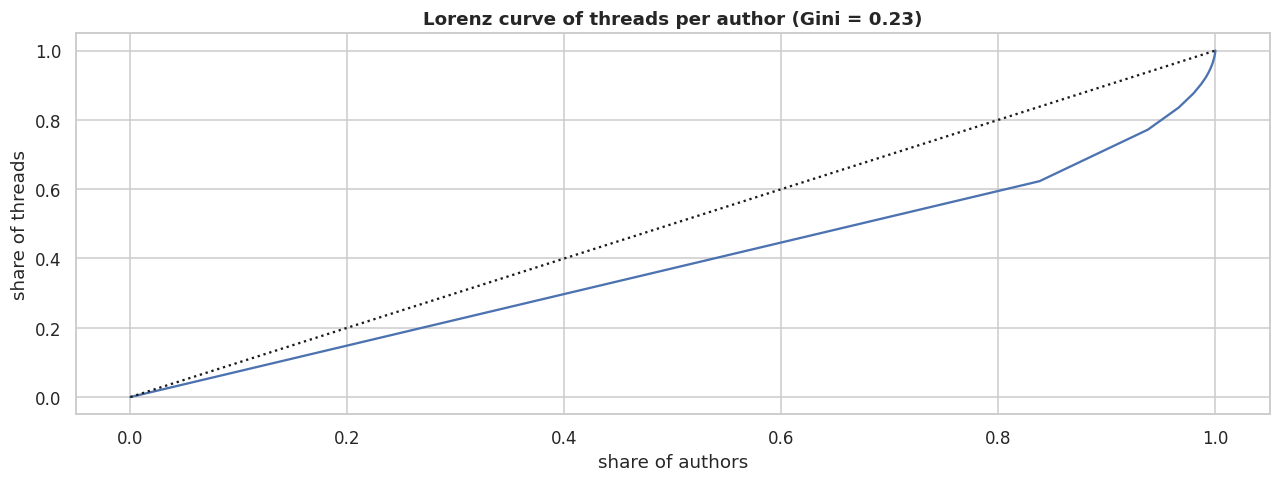

In [ ]:
# @title
n_threads, n_authors = len(df), df.author_id.nunique()

display(pd.Series({'threads': n_threads, 'authors': n_authors}).to_frame('threads and authors'))

a = df.dropna(subset=['author_id']).groupby('author_id').agg(n=('thread_id', 'size'), n_sub=('label', 'nunique'),
                                                             top_share=('label', lambda s: s.value_counts(normalize=True).iloc[0]),
                                                             type=('author_type', 'first'))
pct = a.n.quantile([.5, .75, .9, .95, .99, .999]).rename(lambda q_: f'p{q_*100:g}')
authors_with_one_thread = (a.n == 1).sum()
authors_with_one_thread_pct = authors_with_one_thread / n_authors
display(pd.concat([pct, pd.Series({'max': a.n.max(), 'authors with 1 thread': authors_with_one_thread, 'authors with 1 thread (%)': authors_with_one_thread_pct})]).to_frame('threads per author'))


ig, axes = plt.subplots(figsize=(14, 4.5))
lor = np.r_[0, np.cumsum(np.sort(a.n.values)) / a.n.sum()]
axes.plot(np.linspace(0, 1, len(lor)), lor)
axes.plot([0, 1], [0, 1], 'k:')
gini = 1 - 2 * np.trapezoid(lor, np.linspace(0, 1, len(lor)))
axes.set_title(f'Lorenz curve of threads per author (Gini = {gini:.2f})');
axes.set_xlabel('share of authors')
axes.set_ylabel('share of threads')
plt.show()


#### 2.4 Question Age

All questions crawlled have been created after 2020-01-01. Since we've capped the crawlling at 600 questions per topic, busy topics reach back less.

This means that creation date could be a proxy for the label in some cases. We won't use this meta-data as input to the model but it's worth checking if there is a correlation between the vocabulary and question age.



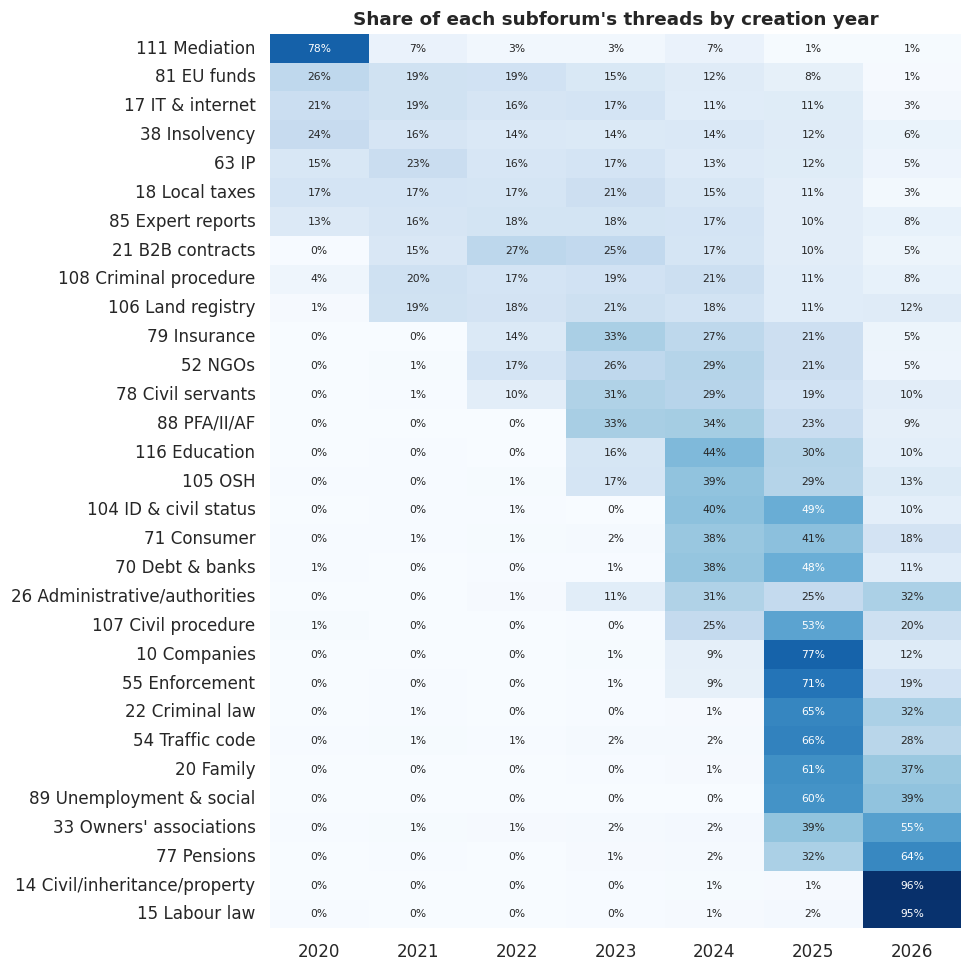

In [ ]:
df['year'] = df.creation_date.dt.year
yr = pd.crosstab(df.label, df.year, normalize='index')
order_age = df.groupby('label').creation_date.median().sort_values().index
yr = yr.loc[order_age]
yr.index = [topic_short_label(i) for i in yr.index]

fig, axes = plt.subplots(figsize=(9, 9))
sns.heatmap(yr, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=axes, annot_kws={'fontsize': 7})
axes.set_title('Share of each subforum\'s threads by creation year')
axes.set_xlabel('')
axes.set_ylabel('')

plt.tight_layout()
plt.show()

#### 2.5 Text lengths

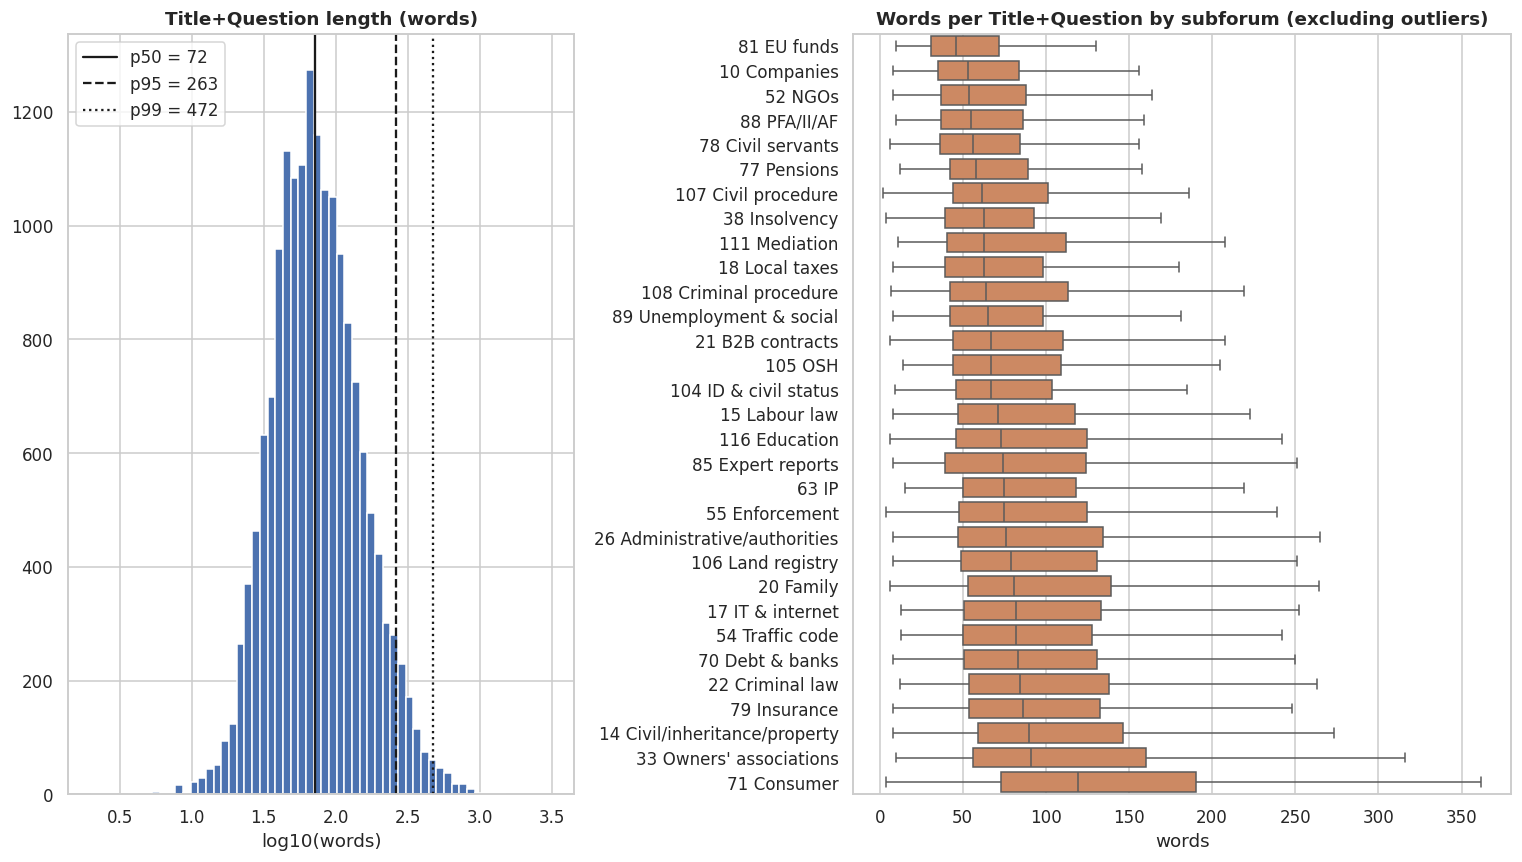

In [ ]:
title_question_word_counts = df["title_question_tokens"].map(len)


fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={'width_ratios': [1, 1.3]})
axes[0].hist(np.log10(title_question_word_counts.clip(lower=1)), bins=60, color='#4c72b0')
axes[0].set_xlabel('log10(words)')
axes[0].set_title('Title+Question length (words)')
for q_, ls in [(.5, '-'), (.95, '--'), (.99, ':')]:
    axes[0].axvline(np.log10(title_question_word_counts.quantile(q_)), color='k', ls=ls, label=f'p{int(q_*100)} = {title_question_word_counts.quantile(q_):.0f}')
axes[0].legend()
order = title_question_word_counts.groupby(df.label).median().sort_values().index
sns.boxplot(x=title_question_word_counts, y=df.label.map(topic_short_label), order=[topic_short_label(i) for i in order], ax=axes[1],
            showfliers=False, color='#dd8452')
# axes[1].set_xscale('log')
axes[1].set_title('Words per Title+Question by subforum (excluding outliers)')
axes[1].set_ylabel('')
axes[1].set_xlabel('words')
plt.tight_layout(); plt.show()

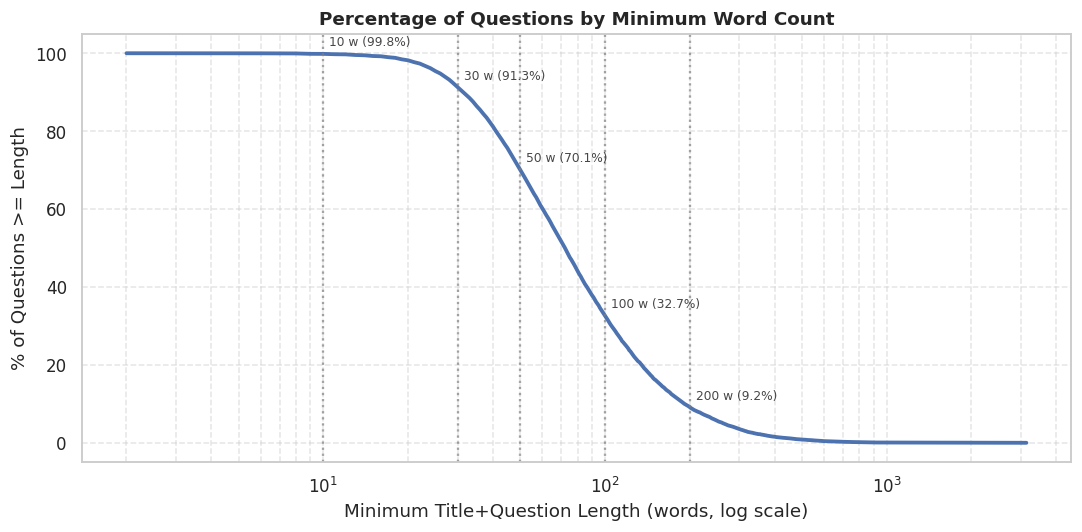

In [ ]:
# Calculate survival function (percentage of questions >= min length)
sorted_lengths = np.sort(title_question_word_counts)
n_total = len(sorted_lengths)
y_pct = (n_total - np.searchsorted(sorted_lengths, sorted_lengths, side='left')) / n_total * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sorted_lengths, y_pct, lw=2.5, color='#4c72b0')
ax.set_xscale('log')
ax.set_title('Percentage of Questions by Minimum Word Count')
ax.set_xlabel('Minimum Title+Question Length (words, log scale)')
ax.set_ylabel('% of Questions >= Length')
ax.grid(True, which="both", ls="--", alpha=0.5)

# TODO: plot by percentage, not by arbitrary question length
# Highlight some common threshold markers
for th in [10, 30, 50, 100, 200]:
    pct_val = (sorted_lengths >= th).mean() * 100
    ax.axvline(x=th, color='gray', linestyle=':', alpha=0.7)
    ax.text(th * 1.05, pct_val + 2, f'{th} w ({pct_val:.1f}%)', fontsize=8, alpha=0.85)

plt.tight_layout()
plt.show()

#### 2.6 Vocabulary


,value
"tokens (normalised, a–z)","1,681,485"
types,"40,420"
types with count = 1 (hapax legomena),"16,565 (41.0% of types)"
types with count ≥ 3 (model vocabulary),"16,277"
types covering 90% of tokens,3845


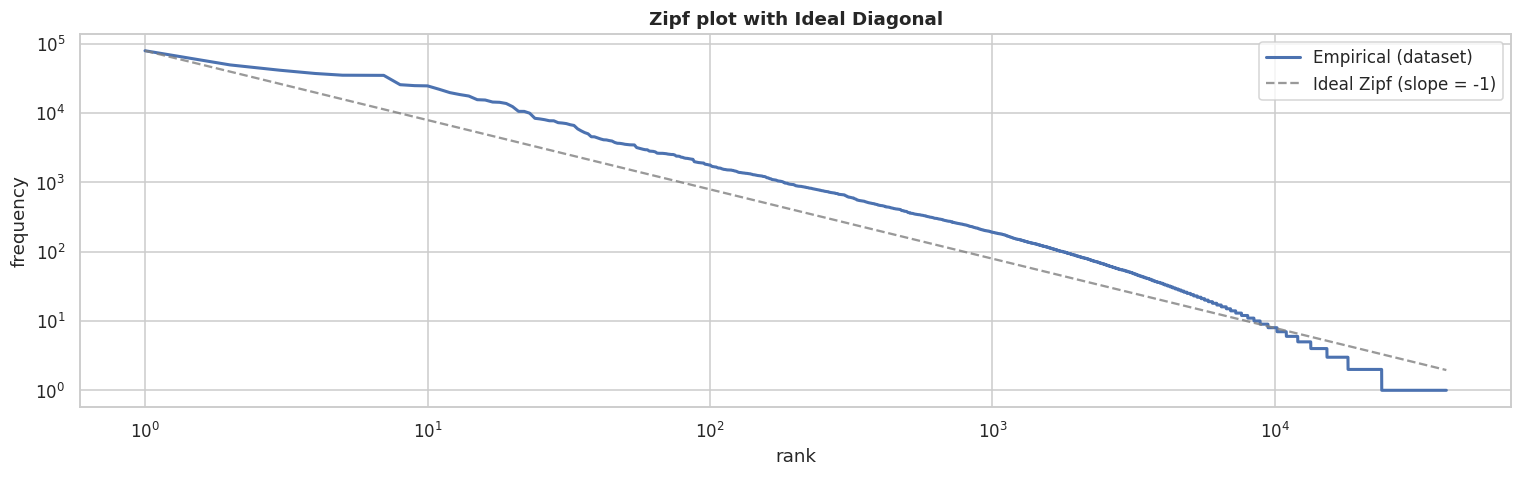

,Top 10 most frequent words
de,4.71%
in,2.94%
si,2.47%
sa,2.21%
am,2.09%
a,2.08%
la,2.08%
ca,1.52%
nu,1.48%
o,1.47%


In [ ]:
count_vec = CountVectorizer(analyzer=lambda toks: [t for t in toks if len(t) >= 2], min_df=3)
COUNTS = count_vec.fit_transform(df['title_question_tokens'])
VOCAB = np.array(count_vec.get_feature_names_out())
TOTAL = np.asarray(COUNTS.sum(0)).ravel().astype(float)

tok_counts = Counter(t for toks in df.title_question_tokens for t in toks)
n_tok = sum(tok_counts.values())
hapax = sum(1 for v in tok_counts.values() if v == 1)
display(pd.Series({
    'tokens (normalised, a–z)': f'{n_tok:,}',
    'types': f'{len(tok_counts):,}',
    'types with count = 1 (hapax legomena)': f'{hapax:,} ({hapax / len(tok_counts):.1%} of types)',
    'types with count ≥ 3 (model vocabulary)': f'{len(VOCAB):,}',
    'types covering 90% of tokens': int(np.searchsorted(np.cumsum(sorted(tok_counts.values(), reverse=True)) / n_tok, .9) + 1),
}).to_frame('value'))

fig, axes = plt.subplots(figsize=(14, 4.5))
freqs = np.array(sorted(tok_counts.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)

# Plot empirical frequencies
axes.loglog(ranks, freqs, label='Empirical (dataset)', color='#4c72b0', lw=2)

# Plot ideal Zipf's Law diagonal (y = C / x)
# We anchor C to the frequency of the most common token
ideal_zipf = freqs[0] / ranks
axes.loglog(ranks, ideal_zipf, label='Ideal Zipf (slope = -1)', color='gray', linestyle='--', alpha=0.8)

axes.set_title('Zipf plot with Ideal Diagonal')
axes.set_xlabel('rank')
axes.set_ylabel('frequency')
axes.legend()
plt.tight_layout(); plt.show()

display(pd.Series({w: f'{count*100/n_tok:.2f}%' for w, count in tok_counts.most_common(10)}).to_frame("Top 10 most frequent words"))

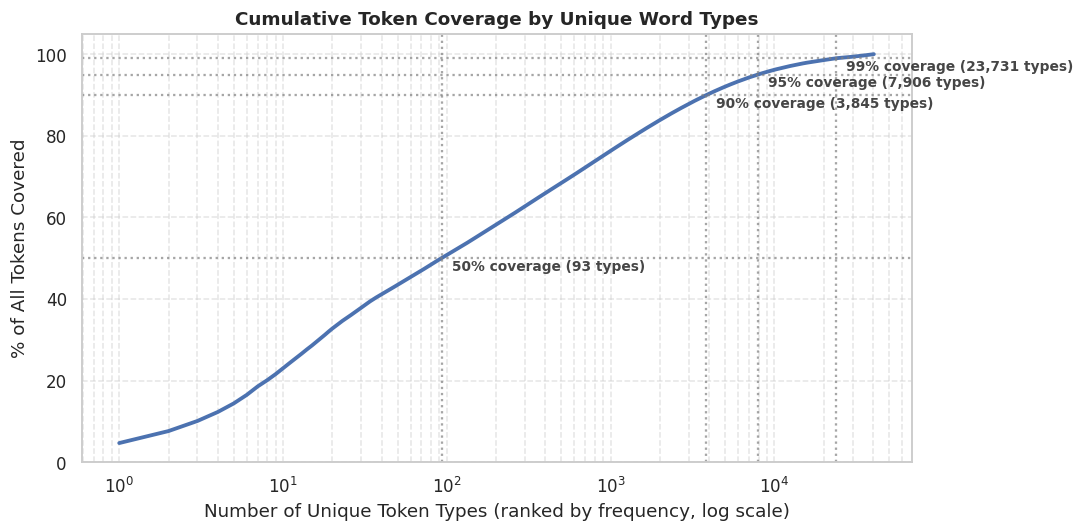

In [ ]:
# Calculate cumulative token coverage by unique token types (sorted from most to least frequent)
sorted_counts = np.array(sorted(tok_counts.values(), reverse=True))
cumulative_coverage = np.cumsum(sorted_counts) / n_tok * 100
ranks = np.arange(1, len(cumulative_coverage) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ranks, cumulative_coverage, lw=2.5, color='#4c72b0')
ax.set_xscale('log')

# Highlight some common coverage threshold markers
for pct_target in [50, 90, 95, 99]:
    idx = np.searchsorted(cumulative_coverage, pct_target)
    types_needed = ranks[idx]
    ax.axhline(y=pct_target, color='gray', linestyle=':', alpha=0.7)
    ax.axvline(x=types_needed, color='gray', linestyle=':', alpha=0.7)
    ax.text(types_needed * 1.15, pct_target - 3, f'{pct_target}% coverage ({types_needed:,} types)', fontsize=9, fontweight='bold', alpha=0.85)

ax.set_title('Cumulative Token Coverage by Unique Word Types')
ax.set_xlabel('Number of Unique Token Types (ranked by frequency, log scale)')
ax.set_ylabel('% of All Tokens Covered')
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

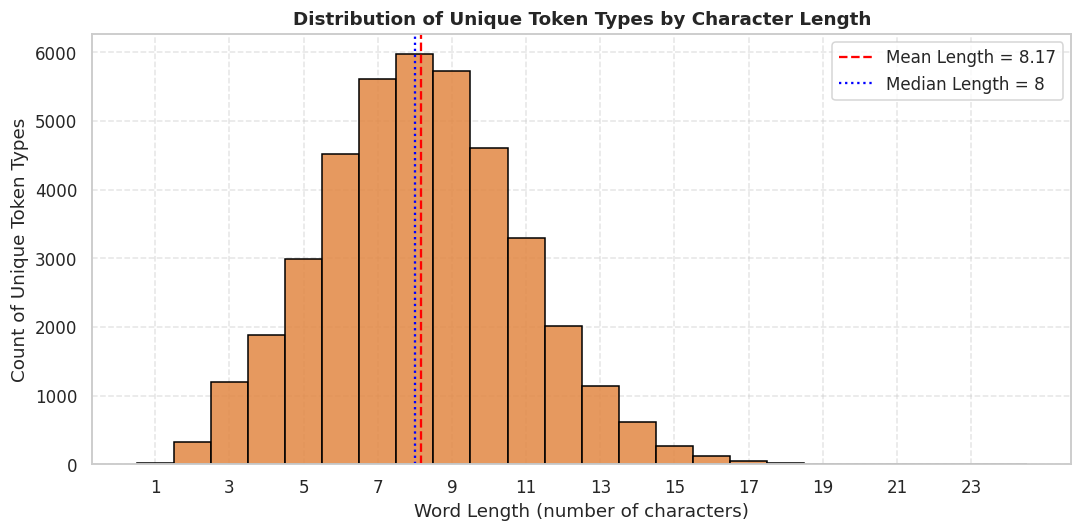

In [ ]:
# Calculate character lengths for all unique token types (vocabulary)
word_types = list(tok_counts.keys())
type_lengths = [len(w) for w in word_types]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(type_lengths, bins=np.arange(0.5, max(type_lengths) + 1.5, 1), color='#e28743', edgecolor='black', alpha=0.85, ax=ax)

# Calculate and plot average/median indicators
mean_len = np.mean(type_lengths)
median_len = np.median(type_lengths)
ax.axvline(mean_len, color='red', linestyle='--', linewidth=1.5, label=f'Mean Length = {mean_len:.2f}')
ax.axvline(median_len, color='blue', linestyle=':', linewidth=1.5, label=f'Median Length = {median_len:.0f}')

ax.set_title('Distribution of Unique Token Types by Character Length')
ax.set_xlabel('Word Length (number of characters)')
ax.set_ylabel('Count of Unique Token Types')
ax.set_xticks(np.arange(1, max(type_lengths) + 1, 2))
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

#### 2.7 Topic Similarity (TF-IDF)

##### 2.7.0 **Duplicates**: TF-IDF cosine

,threads by nearest-neighbour cosine
"[0.0, 0.3)",11200
"[0.3, 0.5)",5200
"[0.5, 0.6)",337
"[0.6, 0.7)",113
"[0.7, 0.8)",41
"[0.8, 0.9)",48
"[0.9, 0.95)",27
"[0.95, 0.999)",45
"[0.999, 1.01)",40


exact duplicates (normalised text): 38 threads


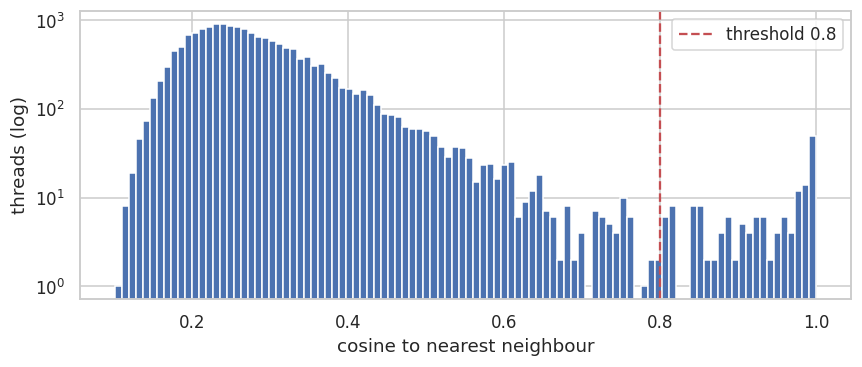

In [ ]:
DUP_THRESHOLD = 0.80
tfidf_dup = TfidfVectorizer(analyzer=lambda toks: toks, sublinear_tf=True, min_df=1)
Xd = tfidf_dup.fit_transform(df.title_question_tokens)
n = Xd.shape[0]
BLOCK = 2000
max_sim = np.zeros(n); nn_idx = np.zeros(n, int); pairs = []
for s in range(0, n, BLOCK):
    S = (Xd[s:s + BLOCK] @ Xd.T).tocsr()
    S = S.toarray()
    S[np.arange(S.shape[0]), np.arange(s, s + S.shape[0])] = 0
    max_sim[s:s + BLOCK] = S.max(1); nn_idx[s:s + BLOCK] = S.argmax(1)
    r, cidx = np.where(S >= DUP_THRESHOLD)
    pairs.append(np.c_[r + s, cidx, S[r, cidx]])

pairs = np.vstack(pairs); pairs = pairs[pairs[:, 0] < pairs[:, 1]]
df['nn_sim'] = max_sim; df['nn_idx'] = nn_idx
exact = df.title_question_tokens.map(' '.join).duplicated(keep=False)

band = pd.cut(max_sim, [0, .3, .5, .6, .7, .8, .9, .95, .999, 1.01], right=False)
display(pd.Series(band).value_counts().sort_index().rename('threads by nearest-neighbour cosine').to_frame())
print(f'exact duplicates (normalised text): {exact.sum()} threads')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(max_sim, bins=100, log=True); ax.axvline(DUP_THRESHOLD, color='r', ls='--', label=f'threshold {DUP_THRESHOLD}')
ax.set_xlabel('cosine to nearest neighbour'); ax.set_ylabel('threads (log)'); ax.legend(); plt.tight_layout(); plt.show()

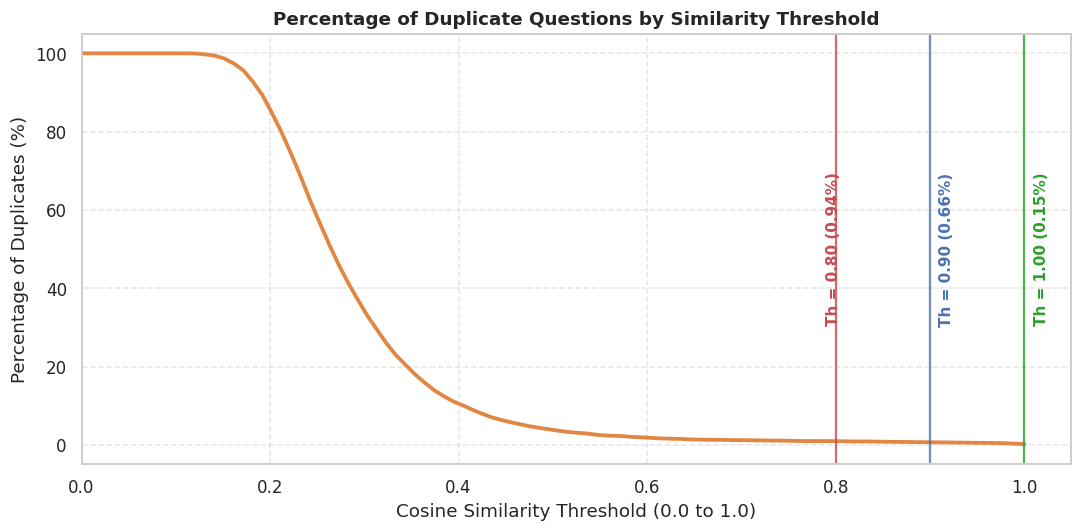

In [ ]:
# Generate thresholds from 0 to 1 with fine granularity
threshold_grid = np.linspace(0.0, 1.0, 100)
pct_duplicates_grid = [(max_sim >= th).mean() * 100 for th in threshold_grid]

# Plot the percentage of duplicates by threshold
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(threshold_grid, pct_duplicates_grid, lw=2.5, color='#e28743')

# Labels and formatting
ax.set_title('Percentage of Duplicate Questions by Similarity Threshold')
ax.set_xlabel('Cosine Similarity Threshold (0.0 to 1.0)')
ax.set_ylabel('Percentage of Duplicates (%)')
ax.set_xlim(0.0, 1.05)
ax.set_ylim(-5, 105)
ax.grid(True, which='both', ls='--', alpha=0.5)

# Highlight key threshold regions using solid vertical lines and offset vertical labels to prevent overlap
configs = [
    {'th': 0.80, 'offset': -0.01, 'ha': 'left', 'color': '#c44e52'},
    {'th': 0.90, 'offset': 0.01, 'ha': 'left', 'color': '#4c72b0'},
    {'th': 1.00, 'offset': 0.01, 'ha': 'left', 'color': '#2ca02c'}
]

for cfg in configs:
    th = cfg['th']
    pct_val = (max_sim >= th).mean() * 100
    ax.axvline(x=th, color=cfg['color'], linestyle='-', linewidth=1.5, alpha=0.8)
    ax.text(
        th + cfg['offset'],
        50,
        f'Th = {th:.2f} ({pct_val:.2f}%)',
        fontsize=10,
        fontweight='bold',
        color=cfg['color'],
        rotation=90,
        va='center',
        ha=cfg['ha']
    )

plt.tight_layout()
plt.show()

##### 2.7.1. **Centroid similarity**: the mean L2-normalised TF-IDF vector of each subforum, cosine between centroids, ordered by average-linkage hierarchical clustering.

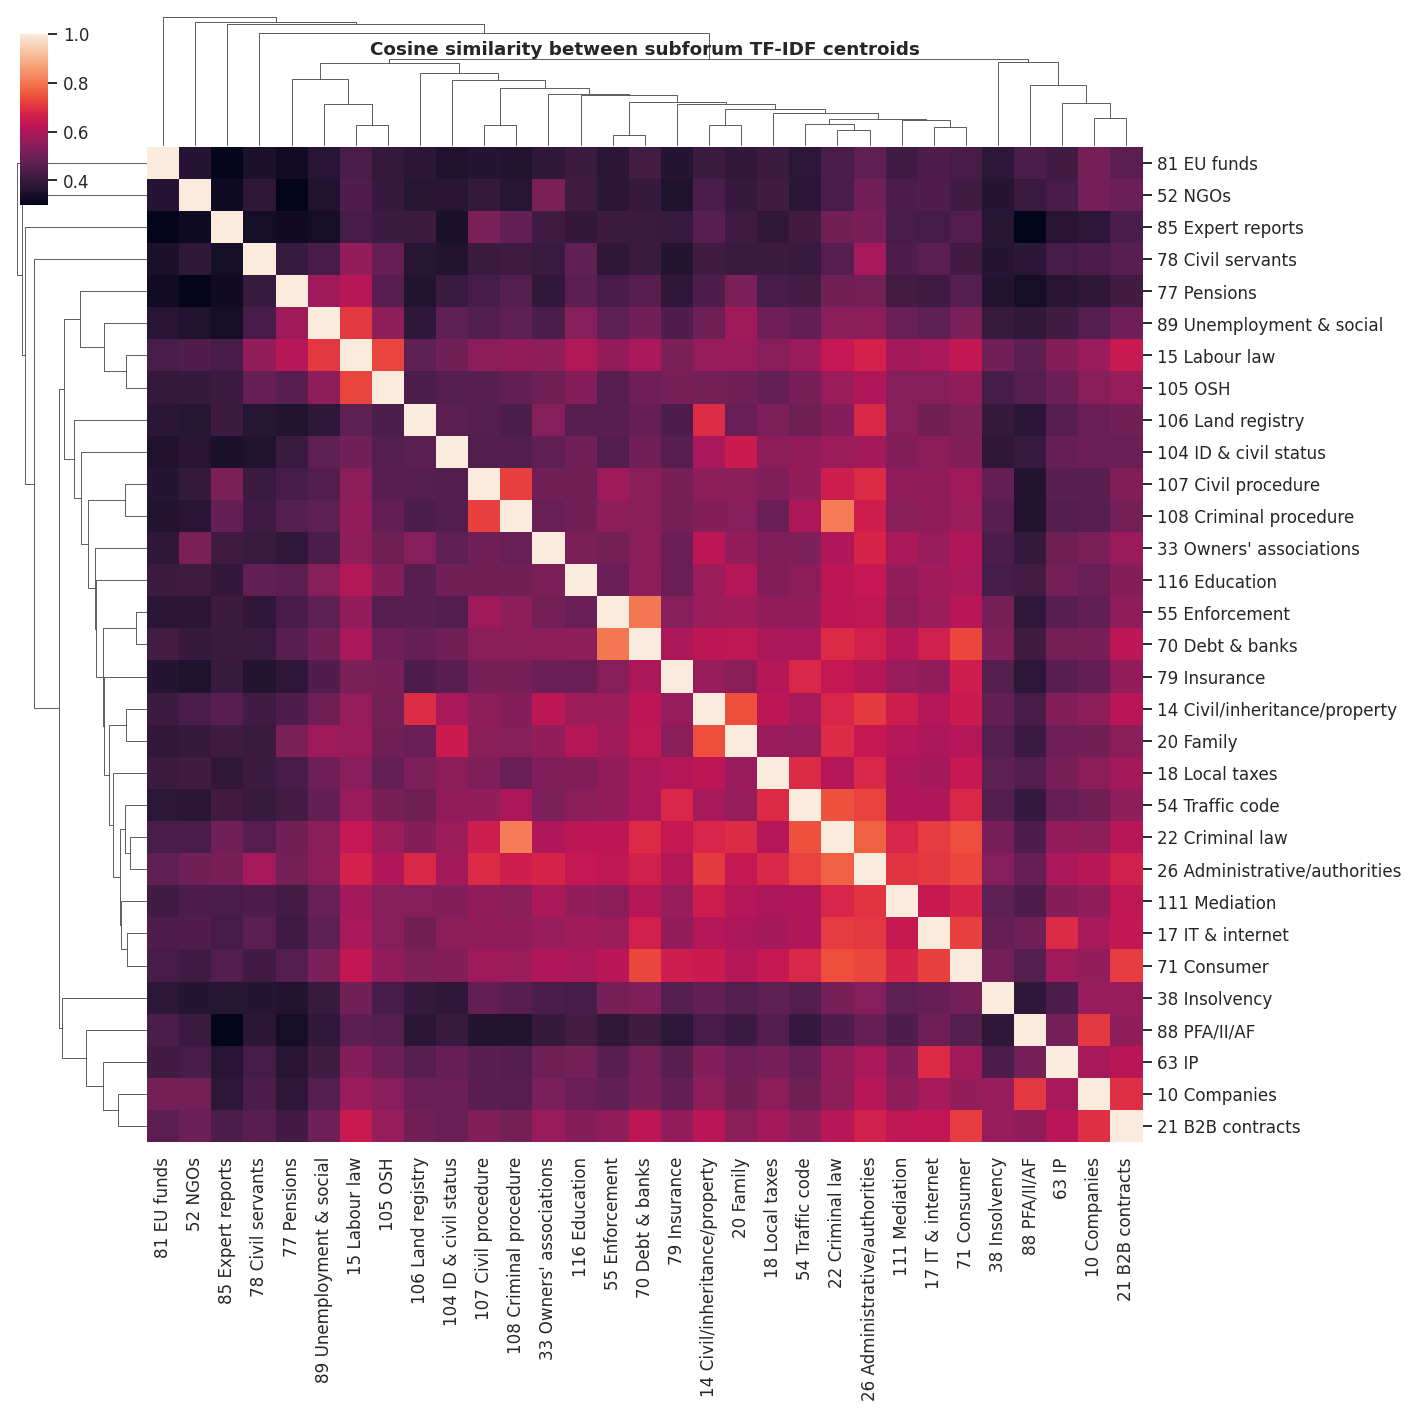

,nearest subforum,cosine
22 Criminal law,108 Criminal procedure,0.811
108 Criminal procedure,22 Criminal law,0.811
55 Enforcement,70 Debt & banks,0.803
70 Debt & banks,55 Enforcement,0.803
26 Administrative/authorities,22 Criminal law,0.766
54 Traffic code,22 Criminal law,0.743
14 Civil/inheritance/property,20 Family,0.742
20 Family,14 Civil/inheritance/property,0.742
71 Consumer,22 Criminal law,0.740
105 OSH,15 Labour law,0.728


In [ ]:
tfidf_topic = TfidfVectorizer(analyzer=lambda toks: toks, sublinear_tf=True, min_df=3, max_df=0.5)
Xt = tfidf_topic.fit_transform(df.title_question_tokens)
cent = np.vstack([np.asarray(Xt[(df.label == c).values].mean(0)).ravel() for c in LABELS])
cent = normalize(cent)
sim = pd.DataFrame(cent @ cent.T, index=[topic_short_label(i) for i in LABELS], columns=[topic_short_label(i) for i in LABELS])
g = sns.clustermap(sim, method='average', metric='cosine', cmap='rocket', figsize=(13, 13),
                   dendrogram_ratio=(.12, .12), cbar_pos=(.02, .85, .02, .12))
g.ax_heatmap.set_title('Cosine similarity between subforum TF-IDF centroids', pad=60); plt.show()

s2 = sim.mask(np.eye(K, dtype=bool))
nearest = pd.DataFrame({'nearest subforum': s2.idxmax(axis=1), 'cosine': s2.max(axis=1)}).sort_values('cosine', ascending=False)
display(nearest.head(12).round(3))

##### 2.7.2. **Unsupervised clustering**: K-means (k = 31) on a 100-d LSA projection of the TF-IDF matrix, compared with the subforum labels (NMI, ARI, homogeneity) and shown as a contingency matrix.

,matched agreement,Cohen's κ,Gwet's AC1
word clusters,34.5%,0.32,0.32
random clusters,4.8%,0.01,0.02


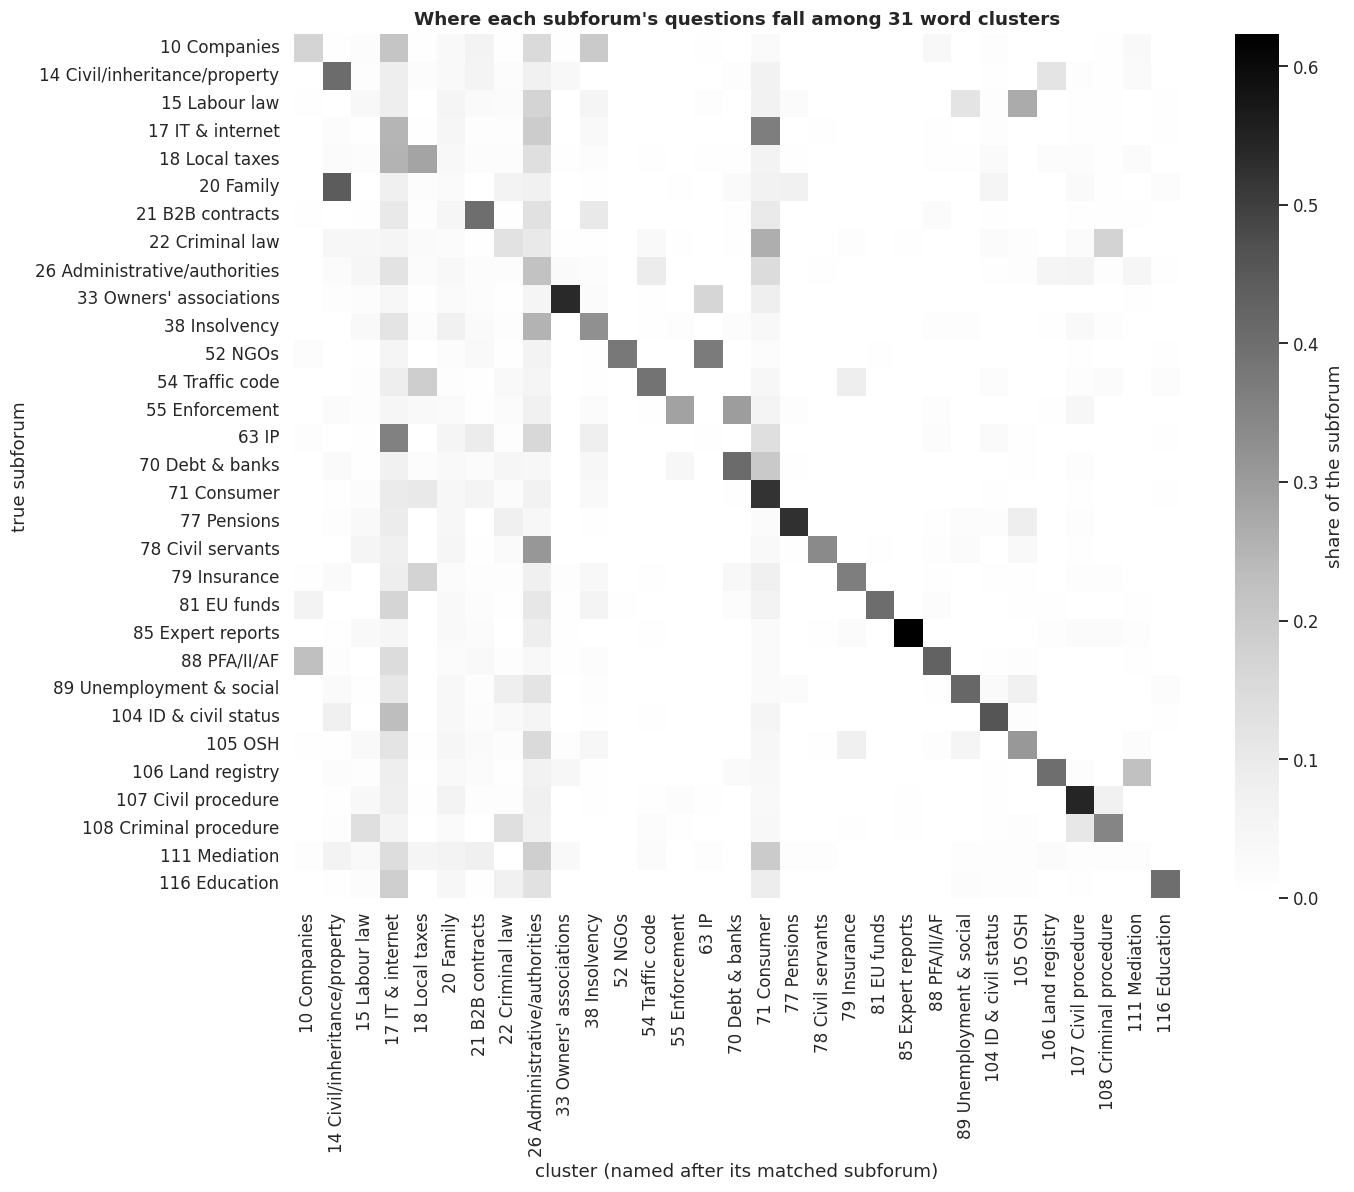

In [ ]:
from scipy.optimize import linear_sum_assignment

# 1. Cluster the questions by their words only
svd = TruncatedSVD(500, random_state=SEED)
Z = normalize(svd.fit_transform(Xt))
clusters = KMeans(n_clusters=K, n_init=5, random_state=SEED).fit_predict(Z)
y = df.label.values

def gwet_ac1(a, b, categories):
    a, b = np.asarray(a), np.asarray(b)
    pa = (a == b).mean()
    pi = np.array([((a == k).mean() + (b == k).mean()) / 2 for k in categories])
    pe = (pi * (1 - pi)).sum() / (len(categories) - 1)
    return (pa - pe) / (1 - pe)

# 2. Pair each cluster with one subforum, maximising the number of matching questions
def match_and_score(cl):
    counts = pd.crosstab(cl, y)
    r, c = linear_sum_assignment(-counts.values)
    mapping = dict(zip(counts.index[r], counts.columns[c]))
    pred = pd.Series(cl).map(mapping).values
    return mapping, np.mean(pred == y), cohen_kappa_score(y, pred, labels=LABELS), gwet_ac1(y, pred, LABELS)

mapping, agree, kappa, gwet = match_and_score(clusters)

# 3. Random reference: shuffle the cluster assignments and do the same
rand = np.array([match_and_score(rng.permutation(clusters))[1:] for _ in range(20)]).mean(0)

display(pd.DataFrame({'matched agreement': [agree, rand[0]], "Cohen's κ": [kappa, rand[1]], "Gwet's AC1": [gwet, rand[2]]},
                     index=['word clusters', 'random clusters']).style.format('{:.1%}', subset='matched agreement')
                                                                  .format('{:.2f}', subset="Cohen's κ")
                                                                  .format('{:.2f}', subset="Gwet's AC1"))

# 4. Heatmap: columns named after the subforum each cluster was paired with
ct = pd.crosstab(df.label, clusters, normalize='index')
ct = ct[[k for k, _ in sorted(mapping.items(), key=lambda kv: LABELS.index(kv[1]))]]
ct.index = [topic_short_label(i) for i in ct.index]
ct.columns = [topic_short_label(mapping[k]) for k in ct.columns]
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(ct, cmap='Greys', ax=ax, cbar_kws={'label': 'share of the subforum'})
ax.set_xlabel('cluster (named after its matched subforum)'); ax.set_ylabel('true subforum')
ax.set_title('Where each subforum\'s questions fall among 31 word clusters')
plt.tight_layout(); plt.show()

### 3. Baselines

We've dropped topic 111 which has only 93 questions, capped every other topic at 400 questions.

We've held out 20% of the questions for validation, stratified by topic

Then we've looked at the following baselines:

- Uniform random - predicting each class with a probability of 1/k
- "Majority" class - a constant prediction of a class
- Logistic regression over raw TF-IDF of title + question

In [ ]:
# Data for the baselines: drop topic 111 (Mediation), cap every topic at 600 questions,
# then hold out 20% of the questions, stratified by topic (each topic keeps the same share in both sets).
from sklearn.model_selection import train_test_split, GridSearchCV

CAP = 400
HOLDOUT_SHARE = 0.20

base = df[df.label != 111]                                         # Mediation: only 92 questions
base = (base.sort_values('creation_date', ascending=False)         # keep the newest 600 per topic,
            .groupby('label').head(CAP)                            # the same rule the crawl used
            .sort_index())
BASE_LABELS = sorted(base.label.unique())

train, holdout = train_test_split(base, test_size=HOLDOUT_SHARE, stratify=base.label, random_state=SEED)
y_train, y_holdout = train.label.values, holdout.label.values
holdout[['thread_id', 'label']].to_csv(OUT_DIR / 'baseline_holdout_ids.csv', index=False)

per_topic = pd.DataFrame({'all': base.label.value_counts(), 'train': train.label.value_counts(),
                          'holdout': holdout.label.value_counts()}).loc[BASE_LABELS]
display(pd.Series({'questions': len(base), 'topics': len(BASE_LABELS),
                   'removed by the cap': int((df.label != 111).sum() - len(base)),
                   'train': len(train), 'holdout': f'{len(holdout)} ({len(holdout) / len(base):.0%})',
                   'holdout questions per topic (min – max)': f'{per_topic.holdout.min()} – {per_topic.holdout.max()}'},
                  name='value').to_frame())

# All three baselines are fitted on `train` and scored once on `holdout` with the same function
BASELINE_RESULTS = {}
def evaluate(name, pred):
    BASELINE_RESULTS[name] = {'macro-F1': f1_score(y_holdout, pred, average='macro', labels=BASE_LABELS),
                              'accuracy': accuracy_score(y_holdout, pred)}
    print(f"{name}: macro-F1 = {BASELINE_RESULTS[name]['macro-F1']:.4f}, "
          f"accuracy = {BASELINE_RESULTS[name]['accuracy']:.4f}")

,value
questions,11646
topics,30
removed by the cap,5313
train,9316
holdout,2330 (20%)
holdout questions per topic (min – max),59 – 80


#### 3.1 Uniform random

Every holdout question gets a topic drawn at random, each of the k = 30 topics with probability 1/k. The model learns nothing from the text or from the training labels.

This is the floor for a model with **no skill at all**: its expected accuracy is 1/k ≈ 3.3%, and with near-balanced topics its expected macro-F1 is also about 1/k. Any useful model has to beat it clearly.

In [ ]:
uniform = DummyClassifier(strategy='uniform', random_state=SEED).fit(train[['thread_id']], y_train)
evaluate('Uniform random', uniform.predict(holdout[['thread_id']]))
print(f'expected value: 1/k = {1 / len(BASE_LABELS):.4f}')

Uniform random: macro-F1 = 0.0334, accuracy = 0.0339
expected value: 1/k = 0.0333


#### 3.2 Majority class

Every holdout question gets the same topic: the most frequent one in the training set.

This baseline shows why **macro-F1** is the main metric. Its accuracy equals that topic's share of the holdout, but its macro-F1 is close to 0: it gets one topic perfectly and the other k − 1 topics completely wrong, and macro-F1 averages over topics.

After the cap, most topics have exactly 400 questions, so several are tied for "most frequent". Scikit-learn then picks the one with the lowest id, which makes the choice arbitrary; any of the tied topics would give the same scores.

In [ ]:
majority = DummyClassifier(strategy='most_frequent').fit(train[['thread_id']], y_train)
evaluate('Majority class', majority.predict(holdout[['thread_id']]))
train_counts = pd.Series(y_train).value_counts()
print(f'predicted topic: {topic_short_label(majority.classes_[majority.class_prior_.argmax()])}  '
      f'({(train_counts == train_counts.max()).sum()} topics tied with {train_counts.max()} training questions)')

Majority class: macro-F1 = 0.0022, accuracy = 0.0343
predicted topic: 10 Companies  (25 topics tied with 320 training questions)


#### 3.3 Logistic regression over raw TF-IDF of title + question

* **Input**: `title_question_tokens`, the normalised title and question (section 1), as plain words: no stemming, no stop-word list.
* **TF-IDF**: sublinear term frequency (1 + log tf), words that appear in at least 2 training questions, words that appear in more than half of the questions dropped. The vocabulary and weights are learned from the training set only.
* **Model**: softmax (multinomial) logistic regression.
* **Regularisation strength `C`**: chosen by 5-fold cross-validation **on the training set** (macro-F1), from {1, 3, 10}. The holdout is used only for the final score.

Below: the three baselines side by side, then the per-topic F1 of the logistic regression.

Original vocabulary shape: (9316, 30443)


CV macro-F1 (train)     std
C  min_df input_dimension                             
1  2      16066                         0.7023  0.0075
   3      12078                         0.7014  0.0067
   5      8605                          0.6997  0.0077
3  2      16066                         0.7112  0.0078
   3      12078                         0.7099  0.0084
   5      8605                          0.7076  0.0092
10 2      16066                         0.7118  0.0092
   3      12078                         0.7068  0.0092
   5      8605                          0.7036  0.0101

chosen best params: {'logisticregression__C': 10, 'tfidfvectorizer__min_df': 2}
LR · TF-IDF (title + question): macro-F1 = 0.7215, accuracy = 0.7197


,macro-F1,accuracy
Uniform random,0.0334,0.0339
Majority class,0.0022,0.0343
LR · TF-IDF (title + question),0.7215,0.7197


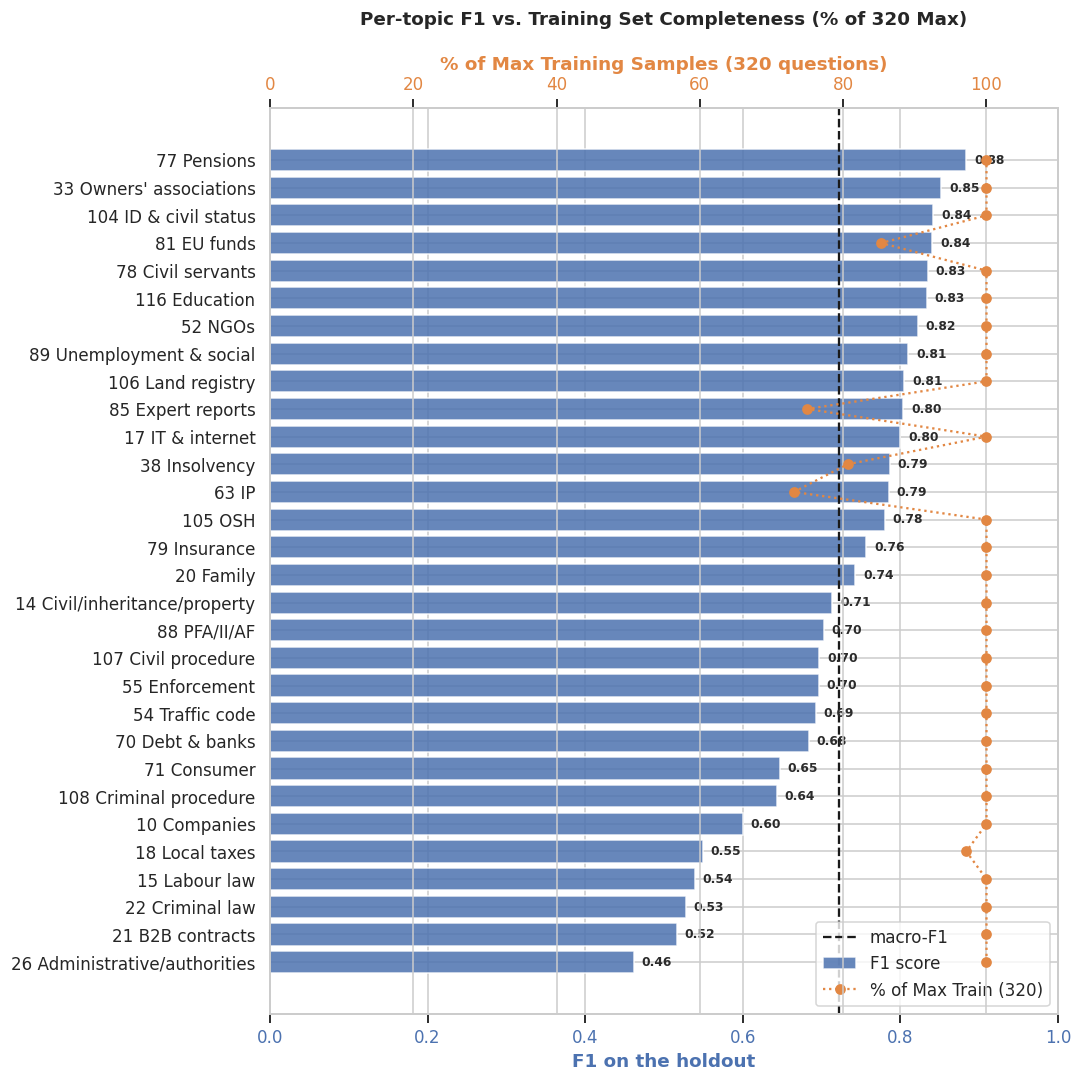

In [ ]:
identity = lambda toks: toks
tfidf_lr_vec = TfidfVectorizer(analyzer=identity, sublinear_tf=True, max_df=0.5)

print("Original vocabulary shape:", tfidf_lr_vec.fit_transform(train['title_question_tokens']).shape)

# Map each min_df to its resulting feature dimension (vocabulary size)
min_df_values = [2, 3, 5]
dim_map = {}
for m_df in min_df_values:
    temp_vec = TfidfVectorizer(analyzer=identity, sublinear_tf=True, max_df=0.5, min_df=m_df)
    dim_map[m_df] = temp_vec.fit_transform(train['title_question_tokens']).shape[1]

# Define Cross-Validation structure
n_folds = 5
cv_splitter = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=SEED)

tfidf_lr = make_pipeline(tfidf_lr_vec, LogisticRegression(max_iter=3000))
search = GridSearchCV(tfidf_lr, {
    'logisticregression__C': [1, 3, 10],
    'tfidfvectorizer__min_df': min_df_values
}, scoring='f1_macro', cv=cv_splitter, n_jobs=-1)
search.fit(train['title_question_tokens'], y_train)

results_df = pd.DataFrame(search.cv_results_)[['param_logisticregression__C', 'param_tfidfvectorizer__min_df', 'mean_test_score', 'std_test_score']]
results_df.columns = ['C', 'min_df', 'CV macro-F1 (train)', 'std']
results_df['input_dimension'] = results_df['min_df'].map(dim_map)

display(results_df.round(4).set_index(['C', 'min_df', 'input_dimension']))
print('chosen best params:', search.best_params_)

lr_pred = search.best_estimator_.predict(holdout['title_question_tokens'])   # refitted on all of train
evaluate('LR · TF-IDF (title + question)', lr_pred)

# All baselines side by side
display(pd.DataFrame(BASELINE_RESULTS).T.style.format('{:.4f}'))
pd.DataFrame(BASELINE_RESULTS).T.to_csv(OUT_DIR / 'baseline_results.csv')

# Per-topic F1 of the logistic regression on the holdout
per_topic_f1 = pd.Series(f1_score(y_holdout, lr_pred, average=None, labels=BASE_LABELS),
                         index=[topic_short_label(i) for i in BASE_LABELS]).sort_values()

# Calculate maximum possible training questions per topic dynamically based on CAP and CV folds
# i.e., 80% of CAP when doing 5-fold CV
max_train_questions = CAP * (1 - 1 / n_folds)

train_counts_aligned = train.label.value_counts().reindex(BASE_LABELS, fill_value=0)
train_pct = (train_counts_aligned / max_train_questions) * 100
train_pct.index = [topic_short_label(i) for i in train_pct.index]
train_pct = train_pct.reindex(per_topic_f1.index)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the primary F1-score bars
ax.barh(per_topic_f1.index, per_topic_f1.values, color='#4c72b0', alpha=0.85, label='F1 score')
ax.axvline(BASELINE_RESULTS['LR · TF-IDF (title + question)']['macro-F1'], color='k', ls='--', label='macro-F1')
for y_, v in enumerate(per_topic_f1.values):
    ax.text(v + .01, y_, f'{v:.2f}', va='center', fontsize=8, fontweight='bold', color='#2b2b2b')

ax.set_xlim(0, 1)
ax.set_xlabel('F1 on the holdout', color='#4c72b0', fontweight='bold')
ax.tick_params(axis='x', labelcolor='#4c72b0')

# Create a twin axis to overlay the % of max training samples
ax2 = ax.twiny()
ax2.plot(train_pct.values, per_topic_f1.index, color='#e28743', marker='o', ls=':', lw=1.5, label=f'% of Max Train ({int(max_train_questions)})')
ax2.set_xlim(0, 110)
ax2.set_xlabel(f'% of Max Training Samples ({int(max_train_questions)} questions)', color='#e28743', fontweight='bold')
ax2.tick_params(axis='x', labelcolor='#e28743')

# Combine legends
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, loc='lower right')

ax.set_title(f'Per-topic F1 vs. Training Set Completeness (% of {int(max_train_questions)} Max)', pad=20)
plt.tight_layout()
plt.show()

### 4. Plan for Phase 2

#### 4.1. Can we improve over the TF-IDF baseline

- Cleaning up the TF-IDF vocabulary - remove stop words, apply stemming
- Adding hand-crafted features:
  - topic-derived lexicon
  - question type (cum?, pot?, unde?)
  - legislation references: art. / alin. / legea / oug


We'll test both standalone and as an addition to the TF-IDF representation.

#### 4.2. What do questions that get mis-classified have in common

We'll check whether it's:
- correlated to the question length
- a topic-wide issue
- because of ambigous questions
- because of mis-labeled questions (submitted to the wrong forum)


#### 4.3. Does scaling the dataset improve the performance

We'll plot the learning curve and train progressively on 25/50/75/100% of the training set originating from the 400-capped dataset.
If improvement seems to continue beyond 100% we have ~200 additional questions per topic to include.

#### 4.4.Does the model benefit from having seen the same author in training

- We'll split the holdout set by "author seen in training" vs "not seen" and compare the scores, noting the size of each group
- Compare models trained with a random split vs author-grouped split

#### 4.5 What's the gain when using dense embeddings

- We'll use two different flavours jurBERT-base and RoBERT-base
- We'll either
  - use the embeddings as input to a logistic regression classifier
  - fine-tune the transformer models for this classification problem